In [5]:
import numpy as np
import matplotlib.pyplot as plt

import re
import requests

!pip install tiktoken
import tiktoken
gpt4Tokenizer = tiktoken.get_encoding('cl100k_base')

In [6]:
# a quick intro to np.unique

nums = np.array([ 1,1,3,2,2,2,9,9,9,-1,-1,-1,-1,-1 ])
uniq,counts = np.unique(nums,return_counts=True)

for n,c in zip(uniq,counts):
  print(f'The number {n:2} appears {c} times.')


# also works for strings?
text = 'Hello, my name is Mike and I like to each chocolate.'
np.unique(text) # nope :(

The number -1 appears 5 times.
The number  1 appears 2 times.
The number  2 appears 3 times.
The number  3 appears 1 times.
The number  9 appears 3 times.


array(['Hello, my name is Mike and I like to each chocolate.'],
      dtype='<U52')

In [7]:
# but this works:
uniq = set(text)
counts = np.zeros(len(uniq),dtype=int)
for i,u in enumerate(uniq):
  counts[i] = text.count(u)

# or using list-comprehension
#counts = [ text.count(u) for u in uniq ]

# print out
for n,c in zip(uniq,counts):
  print(f'The letter "{n}" appears {c:2} times.')

The letter "o" appears  4 times.
The letter "y" appears  1 times.
The letter "m" appears  2 times.
The letter "M" appears  1 times.
The letter "k" appears  2 times.
The letter "," appears  1 times.
The letter "." appears  1 times.
The letter "c" appears  3 times.
The letter "a" appears  4 times.
The letter "s" appears  1 times.
The letter "n" appears  2 times.
The letter "t" appears  2 times.
The letter " " appears 10 times.
The letter "I" appears  1 times.
The letter "l" appears  4 times.
The letter "i" appears  3 times.
The letter "d" appears  1 times.
The letter "H" appears  1 times.
The letter "h" appears  2 times.
The letter "e" appears  6 times.


In [8]:
# all books have the same url format;
# they are unique by numerical code
baseurl = 'https://www.gutenberg.org/cache/epub/'

bookurls = [
    # code       title
    ['84',    'Frankenstein'   ],
    ['64317', 'GreatGatsby'    ],
    ['11',    'AliceWonderland'],
    ['1513',  'RomeoJuliet'    ],
    ['76',    'HuckFinn'       ],
    ['219',   'HeartDarkness'  ],
    ['2591',  'GrimmsTales'    ],
    ['2148',  'EdgarAllenPoe'  ],
    ['36',    'WarOfTheWorlds' ],
    ['829',   'GulliversTravels']
]

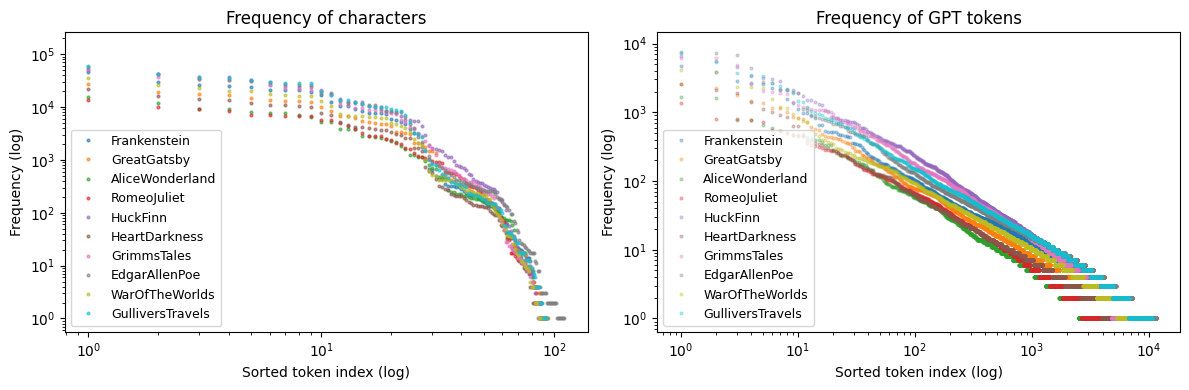

In [10]:
_,axs = plt.subplots(1,2,figsize=(12,4))

for code,title in bookurls:

  # get the text
  fullurl = baseurl + code + '/pg' + code + '.txt'
  text = requests.get(fullurl).text

  # Zipf's law for characters
  counts = [ text.count(u) for u in set(text) ]
  axs[0].plot(np.sort(counts)[::-1],'.',markersize=4,alpha=.6,label=title)

  # and for tokens
  tokens = gpt4Tokenizer.encode(text)
  unitokens,counts = np.unique(tokens,return_counts=True)
  axs[1].plot(np.sort(counts)[::-1],'.',markersize=4,alpha=.3,label=title)
  
  # axis adjustments
for a in axs:
  a.legend(fontsize=9)
  a.set(xscale='log',yscale='log',xlabel='Sorted token index (log)',ylabel='Frequency (log)')

axs[0].set_title('Frequency of characters')
axs[1].set_title('Frequency of GPT tokens')

plt.tight_layout()
plt.show()